# Global Electronics Retailer — Sales & Customer Analytics

## Exploratory Data Analysis

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Visualisation settings
sns.set_theme(style='whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load cleaned datasets

customers = pd.read_csv('../data/processed/Customers_cleaned.csv')
sales = pd.read_csv('../data/processed/Sales_cleaned.csv')
products = pd.read_csv('../data/processed/Products_cleaned.csv')
stores = pd.read_csv('../data/processed/Stores_cleaned.csv')
exchange_rates = pd.read_csv('../data/processed/Exchange_Rates_cleaned.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
# Check dataset dimensions

datasets = {
    'Customers': customers,
    'Sales': sales,
    'Products': products,
    'Stores': stores,
    'Exchange Rates': exchange_rates
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (15266, 10)
Sales: (62884, 9)
Products: (2517, 10)
Stores: (67, 5)
Exchange Rates: (11215, 3)


### Overall Sales Performance Analysis

In [4]:
# Display Sales and Products column names

print("SALES COLUMNS:")
print(sales.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(products.columns.tolist())

SALES COLUMNS:
['Order Number', 'Line Item', 'Order Date', 'Delivery Date', 'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code']

PRODUCTS COLUMNS:
['ProductKey', 'Product Name', 'Brand', 'Color', 'Unit Cost USD', 'Unit Price USD', 'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category']


In [4]:
# Merge sales and products datasets

sales_analysis = sales.merge(
    products[['ProductKey', 'Product Name', 'Unit Price USD']],
    on='ProductKey',
    how='left'
)

# Preview the merged dataset
sales_analysis.head()

,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code,Product Name,Unit Price USD
0,366000,1,2016-01-01,NaN,265598,10,1304,1,CAD,Contoso Lens Adapter M450 White,68.00
1,366001,1,2016-01-01,2016-01-13,1269051,0,1048,2,USD,A. Datum SLR Camera X136 Silver,427.00
2,366001,2,2016-01-01,2016-01-13,1269051,0,2007,1,USD,Fabrikam Microwave 1.5CuFt X1100 Black,665.94
3,366002,1,2016-01-01,2016-01-12,266019,0,1106,7,CAD,Contoso SLR Camera M146 Orange,322.00
4,366002,2,2016-01-01,2016-01-12,266019,0,373,1,CAD,Adventure Works Laptop8.9 E0890 White,326.00


In [5]:
# Overall sales performance

total_sales_lines = sales_analysis.shape[0]

total_units_sold = sales_analysis['Quantity'].sum()

total_estimated_revenue = (
    sales_analysis['Quantity'] *
    sales_analysis['Unit Price USD']
).sum()

average_quantity_per_line = (
    sales_analysis['Quantity'].mean()
)

average_revenue_per_line = (
    total_estimated_revenue / total_sales_lines
)

print("OVERALL SALES PERFORMANCE")
print("-" * 35)

print(f"Total sales lines: {total_sales_lines:,}")
print(f"Total units sold: {total_units_sold:,}")
print(f"Estimated gross revenue: ${total_estimated_revenue:,.2f}")
print(f"Average quantity per line: {average_quantity_per_line:,.2f}")
print(f"Average estimated revenue per line: ${average_revenue_per_line:,.2f}")

OVERALL SALES PERFORMANCE
-----------------------------------
Total sales lines: 62,884
Total units sold: 197,757
Estimated gross revenue: $55,755,479.59
Average quantity per line: 3.14
Average estimated revenue per line: $886.64


In [6]:
# Check for unmatched product records

print("Missing product names:", sales_analysis['Product Name'].isna().sum())
print("Missing unit prices:", sales_analysis['Unit Price USD'].isna().sum())
print("Sales rows after merge:", sales_analysis.shape[0])

Missing product names: 0
Missing unit prices: 0
Sales rows after merge: 62884


### Sales trends over time

In [10]:
# Check the order date data type and range

print("Order Date data type:", sales_analysis['Order Date'].dtype)

print("Earliest order date:", sales_analysis['Order Date'].min())
print("Latest order date:", sales_analysis['Order Date'].max())

Order Date data type: object
Earliest order date: 2016-01-01
Latest order date: 2021-02-20


In [11]:
# Convert Order Date to datetime

sales_analysis['Order Date'] = pd.to_datetime(
    sales_analysis['Order Date']
)

# Verify conversion

print("New data type:", sales_analysis['Order Date'].dtype)

New data type: datetime64[ns]


In [12]:
# Extract year and month from Order Date

sales_analysis['Year'] = sales_analysis['Order Date'].dt.year

sales_analysis['Month'] = sales_analysis['Order Date'].dt.month

sales_analysis['Month Name'] = sales_analysis['Order Date'].dt.month_name()

# Preview the new columns

sales_analysis[
    ['Order Date', 'Year', 'Month', 'Month Name']
].head()

,Order Date,Year,Month,Month Name
0,2016-01-01,2016,1,January
1,2016-01-01,2016,1,January
2,2016-01-01,2016,1,January
3,2016-01-01,2016,1,January
4,2016-01-01,2016,1,January


In [13]:
# Yearly sales performance

yearly_sales = (
    sales_analysis
    .groupby('Year')
    .agg(
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
)

yearly_sales['estimated_revenue'] = yearly_sales['estimated_revenue'].round(2)

yearly_sales

,Year,total_sales_lines,total_units_sold,estimated_revenue
0,2016,6905,21761,"6,946,793.56"
1,2017,7942,24798,"7,421,422.27"
2,2018,14188,44498,"12,788,960.66"
3,2019,21611,68440,"18,264,382.48"
4,2020,11026,34463,"9,294,632.14"
5,2021,1212,3797,"1,039,288.48"


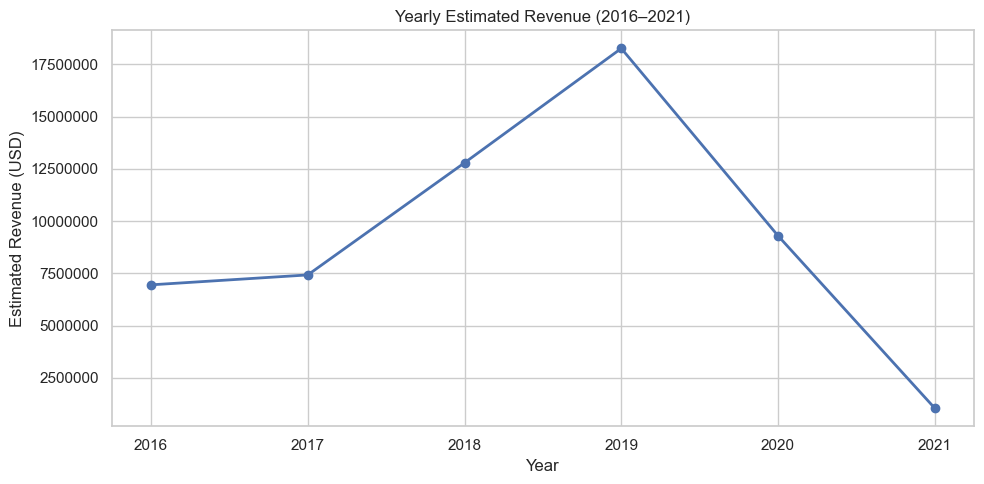

In [15]:
# Plot yearly estimated revenue

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_sales['Year'],
    yearly_sales['estimated_revenue'],
    marker='o',
    linewidth=2
)

plt.title('Yearly Estimated Revenue (2016–2021)')
plt.xlabel('Year')
plt.ylabel('Estimated Revenue (USD)')
plt.xticks(yearly_sales['Year'])
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True)

plt.tight_layout()
plt.show()

In [16]:
# Monthly sales performance

monthly_sales = (
    sales_analysis
    .groupby(['Year', 'Month', 'Month Name'])
    .agg(
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
)

monthly_sales['estimated_revenue'] = monthly_sales['estimated_revenue'].round(2)

monthly_sales.head(15)

,Year,Month,Month Name,total_sales_lines,total_units_sold,estimated_revenue
0,2016,1,January,666,2116,"649,918.78"
1,2016,2,February,815,2676,"891,098.30"
2,2016,3,March,279,895,"338,407.36"
3,2016,4,April,106,326,"110,591.63"
4,2016,5,May,501,1646,"595,986.18"
5,2016,6,June,570,1864,"518,585.28"
6,2016,7,July,512,1572,"454,959.83"
7,2016,8,August,526,1611,"547,512.69"
8,2016,9,September,605,1885,"567,421.12"
9,2016,10,October,628,2042,"623,959.57"


In [17]:
# Average monthly revenue across complete years

average_monthly_revenue = (
    monthly_sales[monthly_sales['Year'].between(2016, 2020)]
    .groupby('Month Name')['estimated_revenue']
    .mean()
    .reindex([
        'January', 'February', 'March', 'April',
        'May', 'June', 'July', 'August',
        'September', 'October', 'November', 'December'
    ])
    .reset_index()
)

average_monthly_revenue.columns = [
    'Month',
    'Average Estimated Revenue'
]

average_monthly_revenue.round(2)

,Month,Average Estimated Revenue
0,January,"1,249,391.92"
1,February,"1,463,241.87"
2,March,"525,104.57"
3,April,"121,466.81"
4,May,"951,596.76"
5,June,"858,607.31"
6,July,"770,483.16"
7,August,"817,033.86"
8,September,"872,772.72"
9,October,"863,005.49"


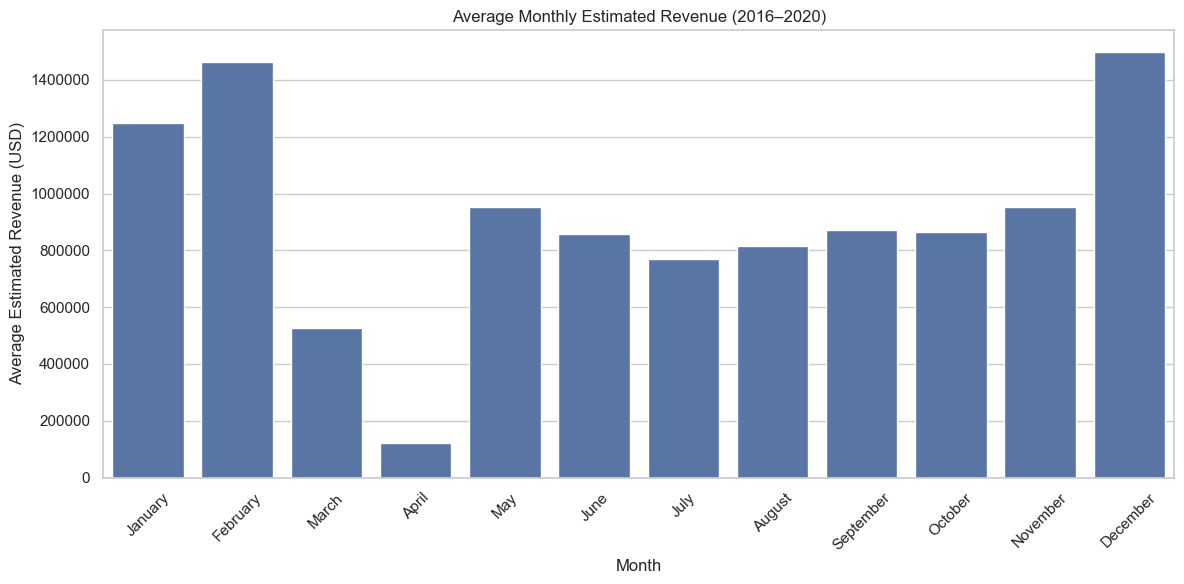

In [18]:
# Visualise average monthly estimated revenue

plt.figure(figsize=(12, 6))

sns.barplot(
    data=average_monthly_revenue,
    x='Month',
    y='Average Estimated Revenue'
)

plt.title('Average Monthly Estimated Revenue (2016–2020)')
plt.xlabel('Month')
plt.ylabel('Average Estimated Revenue (USD)')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

In [22]:
# Merge Sales with the required product information

sales_analysis = sales.merge(
    products[
        [
            'ProductKey',
            'Product Name',
            'Brand',
            'Category',
            'Unit Price USD'
        ]
    ],
    on='ProductKey',
    how='left'
)

# Verify the merge

print(sales_analysis.columns.tolist())
print("Total rows:", sales_analysis.shape[0])
print("Missing categories:", sales_analysis['Category'].isna().sum())

['Order Number', 'Line Item', 'Order Date', 'Delivery Date', 'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code', 'Product Name', 'Brand', 'Category', 'Unit Price USD']
Total rows: 62884
Missing categories: 0


In [23]:
category_sales = (
    sales_analysis
    .groupby('Category')
    .agg(
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
)

category_sales = category_sales.sort_values(
    by='estimated_revenue',
    ascending=False
)

category_sales['estimated_revenue'] = (
    category_sales['estimated_revenue'].round(2)
)

category_sales

,Category,total_sales_lines,total_units_sold,estimated_revenue
3,Computers,14025,44151,"19,301,595.46"
5,Home Appliances,5865,18401,"10,795,478.59"
1,Cameras and camcorders,5559,17609,"6,520,168.02"
2,Cell phones,10158,31477,"6,183,791.22"
7,TV and Video,3558,11236,"5,928,982.69"
0,Audio,7489,23490,"3,169,627.74"
6,"Music, Movies and Audio Books",9169,28802,"3,131,006.44"
4,Games and Toys,7061,22591,"724,829.43"


In [24]:
# Calculate revenue contribution percentage

category_sales['revenue_percentage'] = (
    category_sales['estimated_revenue'] /
    category_sales['estimated_revenue'].sum()
) * 100

category_sales['revenue_percentage'] = (
    category_sales['revenue_percentage'].round(2)
)

category_sales

,Category,total_sales_lines,total_units_sold,estimated_revenue,revenue_percentage
3,Computers,14025,44151,"19,301,595.46",34.62
5,Home Appliances,5865,18401,"10,795,478.59",19.36
1,Cameras and camcorders,5559,17609,"6,520,168.02",11.69
2,Cell phones,10158,31477,"6,183,791.22",11.09
7,TV and Video,3558,11236,"5,928,982.69",10.63
0,Audio,7489,23490,"3,169,627.74",5.68
6,"Music, Movies and Audio Books",9169,28802,"3,131,006.44",5.62
4,Games and Toys,7061,22591,"724,829.43",1.30


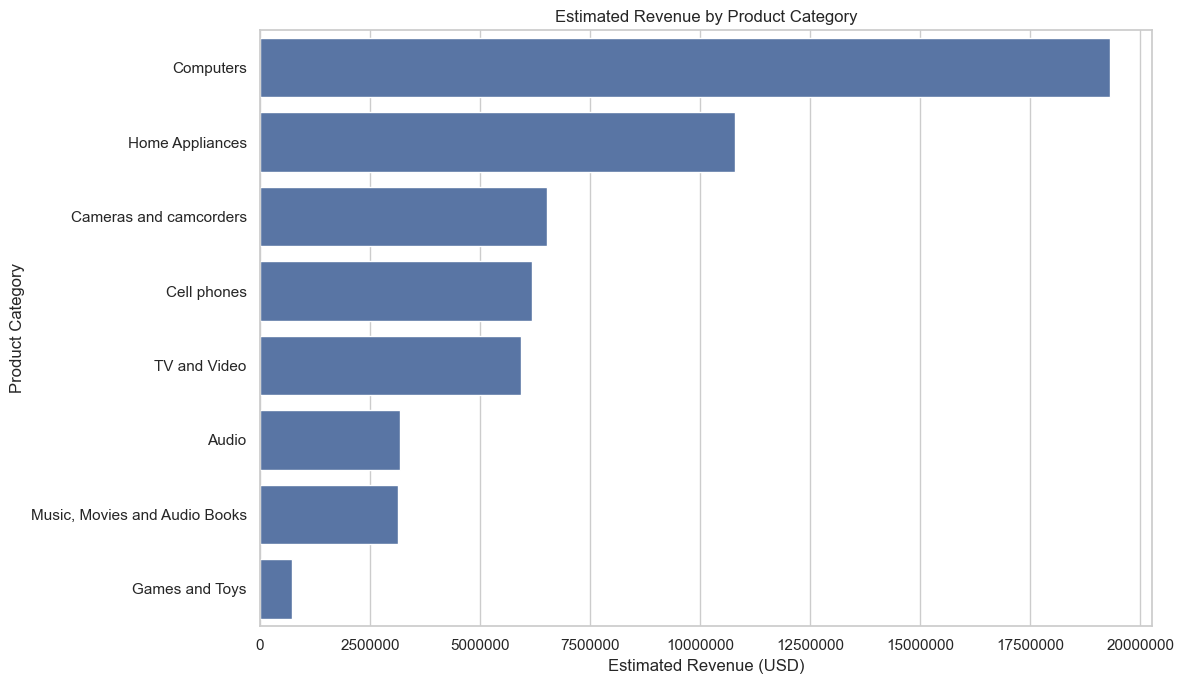

In [25]:
# Visualise estimated revenue by product category

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_sales,
    x='estimated_revenue',
    y='Category'
)

plt.title('Estimated Revenue by Product Category')
plt.xlabel('Estimated Revenue (USD)')
plt.ylabel('Product Category')
plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

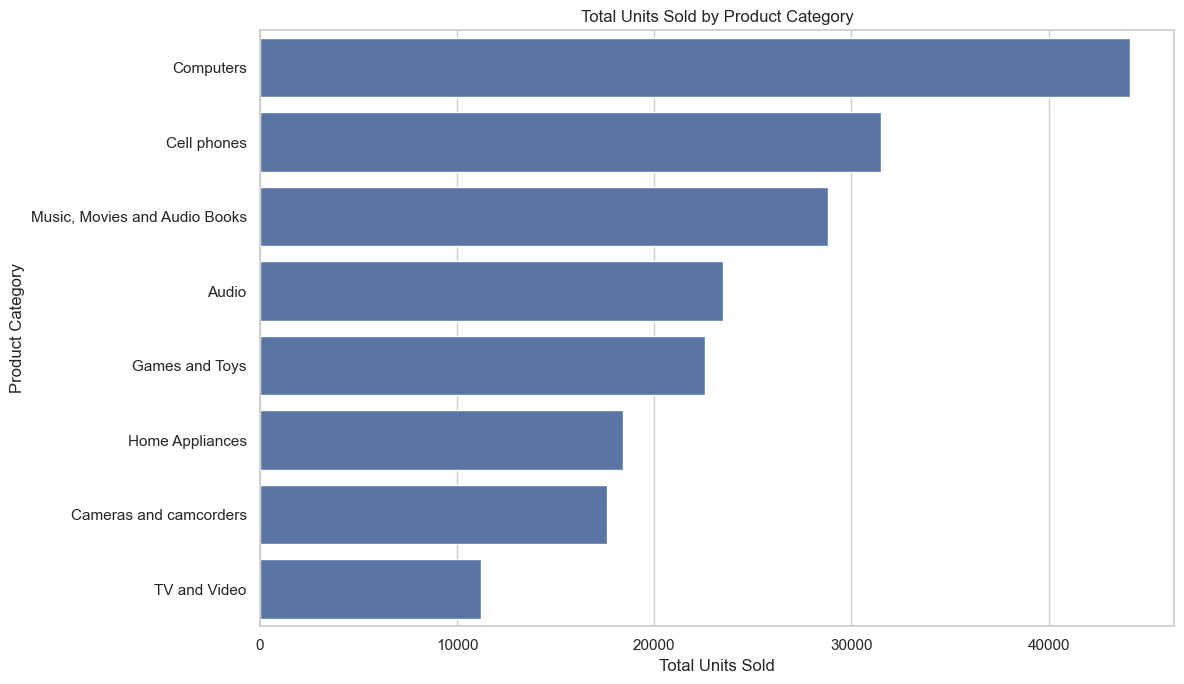

In [26]:
# Visualise units sold by product category

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_sales.sort_values(
        by='total_units_sold',
        ascending=False
    ),
    x='total_units_sold',
    y='Category'
)

plt.title('Total Units Sold by Product Category')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [27]:
# Compare category revenue and sales volume

category_comparison = category_sales[
    ['Category', 'total_units_sold',
     'estimated_revenue', 'revenue_percentage']
].copy()

category_comparison['average_revenue_per_unit'] = (
    category_comparison['estimated_revenue'] /
    category_comparison['total_units_sold']
).round(2)

category_comparison.sort_values(
    by='total_units_sold',
    ascending=False
)

,Category,total_units_sold,estimated_revenue,revenue_percentage,average_revenue_per_unit
3,Computers,44151,"19,301,595.46",34.62,437.17
2,Cell phones,31477,"6,183,791.22",11.09,196.45
6,"Music, Movies and Audio Books",28802,"3,131,006.44",5.62,108.71
0,Audio,23490,"3,169,627.74",5.68,134.94
4,Games and Toys,22591,"724,829.43",1.30,32.08
5,Home Appliances,18401,"10,795,478.59",19.36,586.68
1,Cameras and camcorders,17609,"6,520,168.02",11.69,370.27
7,TV and Video,11236,"5,928,982.69",10.63,527.68


In [28]:
# Top 10 products by estimated revenue

top_products_revenue = (
    sales_analysis
    .groupby('Product Name')
    .agg(
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
    .sort_values(
        by='estimated_revenue',
        ascending=False
    )
    .head(10)
)

top_products_revenue['estimated_revenue'] = (
    top_products_revenue['estimated_revenue'].round(2)
)

top_products_revenue

,Product Name,total_units_sold,estimated_revenue
2381,WWI Desktop PC2.33 X2330 Black,550,"505,450.00"
246,Adventure Works Desktop PC2.33 XD233 Silver,481,"466,089.00"
245,Adventure Works Desktop PC2.33 XD233 Brown,479,"464,151.00"
244,Adventure Works Desktop PC2.33 XD233 Black,462,"447,678.00"
247,Adventure Works Desktop PC2.33 XD233 White,451,"437,019.00"
2384,WWI Desktop PC2.33 X2330 White,462,"424,578.00"
2382,WWI Desktop PC2.33 X2330 Brown,460,"422,740.00"
177,"Adventure Works 52"" LCD HDTV X590 White",136,"394,398.64"
174,"Adventure Works 52"" LCD HDTV X590 Black",129,"374,098.71"
2383,WWI Desktop PC2.33 X2330 Silver,392,"360,248.00"


In [29]:
# Top 10 products by quantity sold

top_products_quantity = (
    sales_analysis
    .groupby('Product Name')
    .agg(
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
    .sort_values(
        by='total_units_sold',
        ascending=False
    )
    .head(10)
)

top_products_quantity['estimated_revenue'] = (
    top_products_quantity['estimated_revenue'].round(2)
)

top_products_quantity

,Product Name,total_units_sold,estimated_revenue
2381,WWI Desktop PC2.33 X2330 Black,550,"505,450.00"
2371,WWI Desktop PC1.80 E1800 White,538,"123,686.20"
228,Adventure Works Desktop PC1.60 ED160 Black,521,"140,643.95"
243,Adventure Works Desktop PC2.30 MD230 White,521,"312,079.00"
232,Adventure Works Desktop PC1.80 ED180 Black,520,"191,880.00"
240,Adventure Works Desktop PC2.30 MD230 Black,514,"307,886.00"
2364,WWI Desktop PC1.60 E1600 Black,509,"111,954.55"
2366,WWI Desktop PC1.60 E1600 Silver,507,"111,514.65"
231,Adventure Works Desktop PC1.60 ED160 White,505,"136,324.75"
2365,WWI Desktop PC1.60 E1600 Red,505,"111,074.75"


In [30]:
# Analyse sales performance by brand

brand_sales = (
    sales_analysis
    .groupby('Brand')
    .agg(
        number_of_products=('ProductKey', 'nunique'),
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
    .sort_values(
        by='estimated_revenue',
        ascending=False
    )
)

brand_sales['estimated_revenue'] = (
    brand_sales['estimated_revenue'].round(2)
)

brand_sales

,Brand,number_of_products,total_sales_lines,total_units_sold,estimated_revenue
1,Adventure Works,183,6382,20099,"11,849,909.32"
2,Contoso,708,15953,49827,"10,792,325.32"
10,Wide World Importers,170,8680,27413,"9,172,800.41"
3,Fabrikam,267,3560,11384,"6,807,893.52"
9,The Phone Company,152,6062,18764,"5,386,820.00"
6,Proseware,239,2995,9427,"3,212,628.02"
4,Litware,258,1663,5309,"2,659,498.78"
7,Southridge Video,192,7887,24814,"2,578,595.93"
0,A. Datum,132,1834,5655,"1,486,207.80"
5,Northwind Traders,47,2411,7610,"1,126,069.54"


In [31]:
# Calculate each brand's revenue contribution

brand_sales['revenue_percentage'] = (
    brand_sales['estimated_revenue'] /
    brand_sales['estimated_revenue'].sum()
) * 100

brand_sales['revenue_percentage'] = (
    brand_sales['revenue_percentage'].round(2)
)

brand_sales

,Brand,number_of_products,total_sales_lines,total_units_sold,estimated_revenue,revenue_percentage
1,Adventure Works,183,6382,20099,"11,849,909.32",21.25
2,Contoso,708,15953,49827,"10,792,325.32",19.36
10,Wide World Importers,170,8680,27413,"9,172,800.41",16.45
3,Fabrikam,267,3560,11384,"6,807,893.52",12.21
9,The Phone Company,152,6062,18764,"5,386,820.00",9.66
6,Proseware,239,2995,9427,"3,212,628.02",5.76
4,Litware,258,1663,5309,"2,659,498.78",4.77
7,Southridge Video,192,7887,24814,"2,578,595.93",4.62
0,A. Datum,132,1834,5655,"1,486,207.80",2.67
5,Northwind Traders,47,2411,7610,"1,126,069.54",2.02


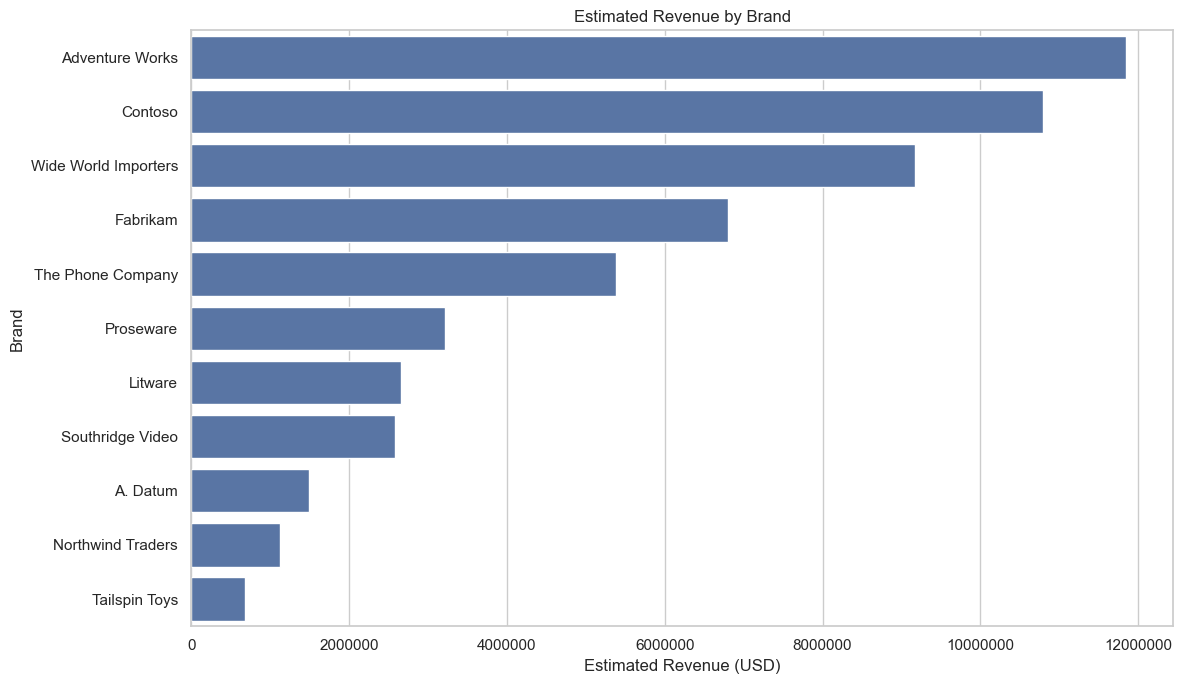

In [32]:
# Visualise estimated revenue by brand

plt.figure(figsize=(12, 7))

sns.barplot(
    data=brand_sales,
    x='estimated_revenue',
    y='Brand'
)

plt.title('Estimated Revenue by Brand')
plt.xlabel('Estimated Revenue (USD)')
plt.ylabel('Brand')
plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

In [34]:
# Top 10 customers by estimated revenue

customer_sales = (
    sales_analysis
    .groupby('CustomerKey')
    .agg(
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=(
            'Quantity',
            lambda x: (
                x * sales_analysis.loc[x.index, 'Unit Price USD']
            ).sum()
        )
    )
    .reset_index()
)

# Attach customer names

customer_sales = customer_sales.merge(
    customers[['CustomerKey', 'Name', 'Country']],
    on='CustomerKey',
    how='left'
)

# Sort and display the top 10

top_customers_revenue = (
    customer_sales
    .sort_values('estimated_revenue', ascending=False)
    .head(10)
)

top_customers_revenue['estimated_revenue'] = (
    top_customers_revenue['estimated_revenue'].round(2)
)

top_customers_revenue[
    ['Name', 'Country', 'total_sales_lines',
     'total_units_sold', 'estimated_revenue']
]

,Name,Country,total_sales_lines,total_units_sold,estimated_revenue
9371,Matthew Flemming,United States,21,75,"61,871.70"
10515,Karen Jones,United States,9,30,"43,517.80"
11072,Zrina Topic,United States,18,60,"42,788.04"
2743,Stefanie Hartmann,Germany,10,35,"41,521.53"
2840,Stephan Rothstein,Germany,10,36,"40,556.54"
3664,Gaspare Trevisan,Italy,36,124,"40,225.01"
1175,Roy Le,Canada,10,32,"38,813.88"
10795,Dennis Weissmuller,United States,13,40,"38,191.06"
8116,Virgie Takacs,United States,8,29,"37,319.88"
7275,Ollie Davis,United States,21,62,"36,817.28"


In [35]:
# Check for duplicate customer records

print(
    "Unique CustomerKeys in customers:",
    customers['CustomerKey'].nunique()
)

print(
    "Total customer rows:",
    len(customers)
)

print(
    "Unique CustomerKeys in customer_sales:",
    customer_sales['CustomerKey'].nunique()
)

print(
    "Customer records missing names:",
    customer_sales['Name'].isna().sum()
)

print(
    "Total customer sales revenue:",
    round(customer_sales['estimated_revenue'].sum(), 2)
)

Unique CustomerKeys in customers: 15266
Total customer rows: 15266
Unique CustomerKeys in customer_sales: 11887
Customer records missing names: 0
Total customer sales revenue: 55755479.59


In [36]:
top_customers_quantity = (
    customer_sales
    .sort_values('total_units_sold', ascending=False)
    .head(10)
)

top_customers_quantity[
    ['Name', 'Country', 'total_sales_lines',
     'total_units_sold', 'estimated_revenue']
]

,Name,Country,total_sales_lines,total_units_sold,estimated_revenue
3664,Gaspare Trevisan,Italy,36,124,"40,225.01"
10775,Fabrice Lamoureux,United States,32,123,"26,339.39"
2331,Vanessa Holzman,Germany,25,107,"21,502.52"
9598,Martha Thornton,United States,23,103,"28,425.35"
8597,Paul Warren,United States,32,100,"35,780.33"
11094,Claire Macdonald,United States,29,98,"28,869.45"
7379,David Breton,United States,27,95,"25,236.97"
7599,Michael Hermes,United States,22,95,"28,270.19"
6732,Frances Colbert,United States,23,95,"27,443.91"
4742,Kayleigh Power,United Kingdom,20,93,"21,455.47"


In [37]:
top_revenue_names = set(top_customers_revenue['Name'])
top_quantity_names = set(top_customers_quantity['Name'])

common_customers = top_revenue_names.intersection(top_quantity_names)

print("Customers appearing in both top 10 lists:")
print(common_customers)
print("\nNumber of overlapping customers:", len(common_customers))

Customers appearing in both top 10 lists:
{'Gaspare Trevisan'}

Number of overlapping customers: 1


In [38]:
country_customer_analysis = (
    customer_sales.groupby('Country')
    .agg(
        total_customers=('CustomerKey', 'nunique'),
        total_units_sold=('total_units_sold', 'sum'),
        estimated_revenue=('estimated_revenue', 'sum')
    )
    .reset_index()
    .sort_values('estimated_revenue', ascending=False)
)

country_customer_analysis.head(10)

,Country,total_customers,total_units_sold,estimated_revenue
7,United States,5706,106407,"29,871,631.17"
6,United Kingdom,1570,25298,"7,084,088.12"
3,Germany,1150,18943,"5,414,149.80"
1,Canada,1179,16793,"4,724,334.63"
0,Australia,780,9209,"2,708,137.61"
4,Italy,530,8470,"2,475,645.77"
5,Netherlands,534,7252,"1,962,154.27"
2,France,438,5385,"1,515,338.22"


In [39]:
country_customer_analysis['avg_revenue_per_customer'] = (
    country_customer_analysis['estimated_revenue'] /
    country_customer_analysis['total_customers']
)

country_customer_analysis.sort_values(
    'avg_revenue_per_customer',
    ascending=False
)

,Country,total_customers,total_units_sold,estimated_revenue,avg_revenue_per_customer
7,United States,5706,106407,"29,871,631.17","5,235.13"
3,Germany,1150,18943,"5,414,149.80","4,707.96"
4,Italy,530,8470,"2,475,645.77","4,671.03"
6,United Kingdom,1570,25298,"7,084,088.12","4,512.16"
1,Canada,1179,16793,"4,724,334.63","4,007.07"
5,Netherlands,534,7252,"1,962,154.27","3,674.45"
0,Australia,780,9209,"2,708,137.61","3,471.97"
2,France,438,5385,"1,515,338.22","3,459.68"


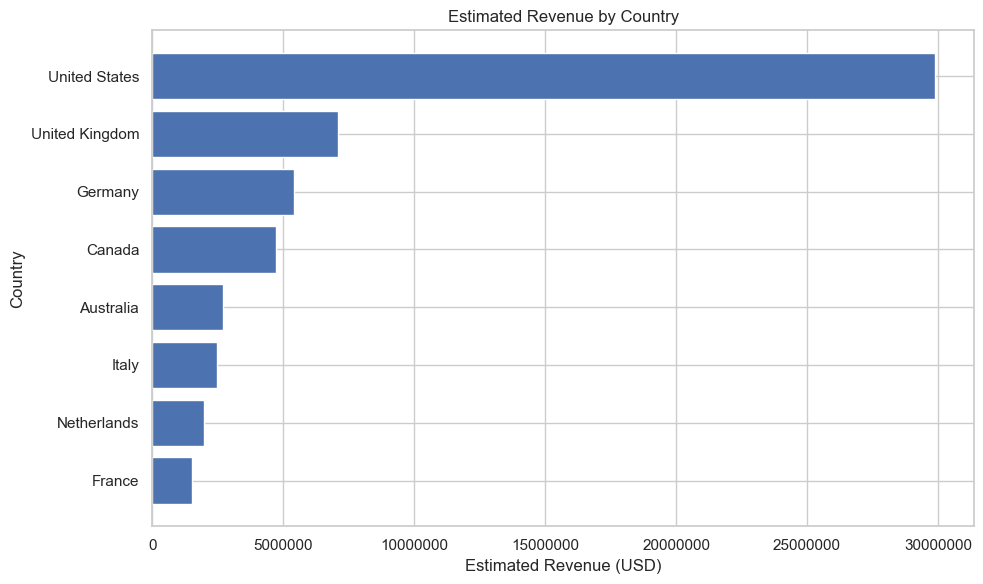

In [40]:
country_revenue_sorted = country_customer_analysis.sort_values(
    'estimated_revenue',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    country_revenue_sorted['Country'],
    country_revenue_sorted['estimated_revenue']
)

plt.title('Estimated Revenue by Country')
plt.xlabel('Estimated Revenue (USD)')
plt.ylabel('Country')
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

In [44]:
store_sales = (
    sales
    .merge(
        products[['ProductKey', 'Unit Price USD']],
        on='ProductKey',
        how='left'
    )
    .merge(
        stores[['StoreKey', 'Country', 'State', 'Square Meters']],
        on='StoreKey',
        how='left'
    )
)

store_sales['estimated_revenue'] = (
    store_sales['Quantity'] * store_sales['Unit Price USD']
)



print("Rows:", len(store_sales))
print("Missing product prices:", store_sales['Unit Price USD'].isna().sum())
print("Missing store locations:", store_sales['Country'].isna().sum())
print("Total estimated revenue:", round(store_sales['estimated_revenue'].sum(), 2))

Rows: 62884
Missing product prices: 0
Missing store locations: 0
Total estimated revenue: 55755479.59


In [45]:
store_sales['store_type'] = np.where(
    store_sales['StoreKey'] == 0,
    'Online',
    'Physical Store'
)

channel_performance = (
    store_sales.groupby('store_type')
    .agg(
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=('estimated_revenue', 'sum')
    )
    .reset_index()
)

channel_performance['revenue_share'] = (
    channel_performance['estimated_revenue'] /
    channel_performance['estimated_revenue'].sum() * 100
)

channel_performance

,store_type,total_sales_lines,total_units_sold,estimated_revenue,revenue_share
0,Online,13165,41311,"11,404,324.63",20.45
1,Physical Store,49719,156446,"44,351,154.96",79.55


In [46]:
physical_store_sales = store_sales[
    store_sales['StoreKey'] != 0
]

store_efficiency = (
    physical_store_sales.groupby(
        ['StoreKey', 'Country', 'State', 'Square Meters']
    )
    .agg(
        total_sales_lines=('Order Number', 'count'),
        total_units_sold=('Quantity', 'sum'),
        estimated_revenue=('estimated_revenue', 'sum')
    )
    .reset_index()
)

store_efficiency['revenue_per_sqm'] = (
    store_efficiency['estimated_revenue'] /
    store_efficiency['Square Meters']
)

top_stores_efficiency = store_efficiency.sort_values(
    'revenue_per_sqm',
    ascending=False
).head(10)

top_stores_efficiency

,StoreKey,Country,State,Square Meters,total_sales_lines,total_units_sold,estimated_revenue,revenue_per_sqm
56,66,United States,Wyoming,840.00,1295,3986,"1,220,964.38","1,453.53"
37,43,United States,Alaska,"1,190.00",1340,4258,"1,250,255.14","1,050.63"
40,47,United States,Hawaii,"1,120.00",1348,4220,"1,130,742.94","1,009.59"
48,56,United States,New Hampshire,"1,260.00",1287,4130,"1,207,253.73",958.14
45,53,United States,Montana,"1,260.00",1284,4078,"1,193,921.14",947.56
54,64,United States,Washington DC,"1,330.00",1353,4289,"1,259,350.98",946.88
24,29,Italy,Enna,"1,000.00",1011,3144,"913,856.35",913.86
6,9,Canada,Northwest Territories,"1,500.00",1577,4894,"1,336,150.06",890.77
44,51,United States,Maine,"1,295.00",1356,4095,"1,130,592.31",873.04
7,10,Canada,Nunavut,"1,210.00",1269,3909,"1,043,185.80",862.14


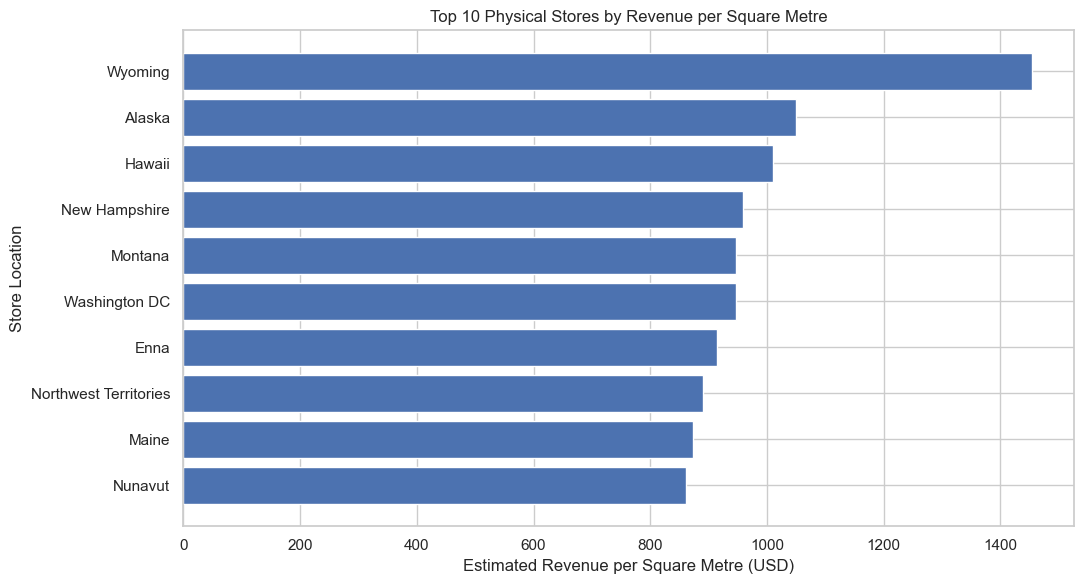

In [47]:
plt.figure(figsize=(11, 6))

plt.barh(
    top_stores_efficiency.sort_values('revenue_per_sqm')['State'],
    top_stores_efficiency.sort_values('revenue_per_sqm')['revenue_per_sqm']
)

plt.title('Top 10 Physical Stores by Revenue per Square Metre')
plt.xlabel('Estimated Revenue per Square Metre (USD)')
plt.ylabel('Store Location')
plt.tight_layout()
plt.show()